# 1. Cleaning, and why it changed the answers

The data is a year of orders from a UK online gift retailer: about 540,000 rows from December 2010 to December 2011.

The first version of this project removed return rows and moved on. This notebook shows why that was not enough, and what the cleaned data looks like.

In [1]:
import os, sys
if os.path.basename(os.getcwd()) == "notebooks":
    os.chdir("..")
sys.path.insert(0, "src")
import numpy as np
import pandas as pd
import matplotlib.pyplot as plt
from matplotlib.ticker import LogLocator
from retail_analysis.clean import SHOPS, load, clean, open_shop
from retail_analysis.segmentation import GROUPS

plt.style.use("dark_background")
plt.rcParams.update({"figure.facecolor": "black", "axes.facecolor": "black", "axes.edgecolor": "#3a3b3e", "axes.grid": True,
                     "grid.color": "#1c1c1e", "figure.figsize": (11, 4.5), "axes.axisbelow": True, "axes.spines.top": False, "axes.spines.right": False})
WHITE, SILVER, GREY, JADE, RED = "#f2f2f0", "#d4d6da", "#8d8d90", "#5fd0a0", "#e0787a"
COLORS = dict(zip(GROUPS, ["#7fb4d8", JADE, "#9fd9bd", WHITE, SILVER, "#c9a25a", GREY]))
money = lambda v, _=None: f"£{v:,.0f}"
UK, AMAZON, GROCERY = SHOPS

sales, removed = open_shop(UK)
raw = load(SHOPS[UK]["file"])

## What gets removed

In [2]:
pd.Series(removed).to_frame("count").style.format("{:,.0f}")

,count
rows at the start,"541,909"
no customer on the row,"135,080"
"fees, postage and adjustments","1,920"
return rows,"8,539"
units returned and taken off sales,"250,677"
rows at the end,"393,529"


## The two orders that bent everything

The two largest orders in the file were each cancelled within minutes. Removing only the cancellation row leaves the sale behind.

In [3]:
big = raw.assign(value=raw.quantity * raw.price)
big = big[big["product"].isin(["23843", "23166"]) & (big.quantity.abs() > 70000)]
big[["order", "name", "quantity", "price", "customer", "when", "value"]].style.format({"value": "£{:,.0f}", "quantity": "{:,.0f}", "customer": "{:.0f}"})

,order,name,quantity,price,customer,when,value
61619,541431,MEDIUM CERAMIC TOP STORAGE JAR,"74,215",1.040000,12346,2011-01-18 10:01:00,"£77,184"
61624,C541433,MEDIUM CERAMIC TOP STORAGE JAR,"-74,215",1.040000,12346,2011-01-18 10:17:00,"£-77,184"
540421,581483,"PAPER CRAFT , LITTLE BIRDIE","80,995",2.080000,16446,2011-12-09 09:15:00,"£168,470"
540422,C581484,"PAPER CRAFT , LITTLE BIRDIE","-80,995",2.080000,16446,2011-12-09 09:27:00,"£-168,470"


An 80,995 unit order placed at 9:15 and cancelled at 9:27. In the first version of this project that order made **Paper Craft, Little Birdie** the top product by revenue and made its buyer one of the top customers. Neither is true.

The fix: each return is taken off that customer's most recent earlier purchase of the same product.

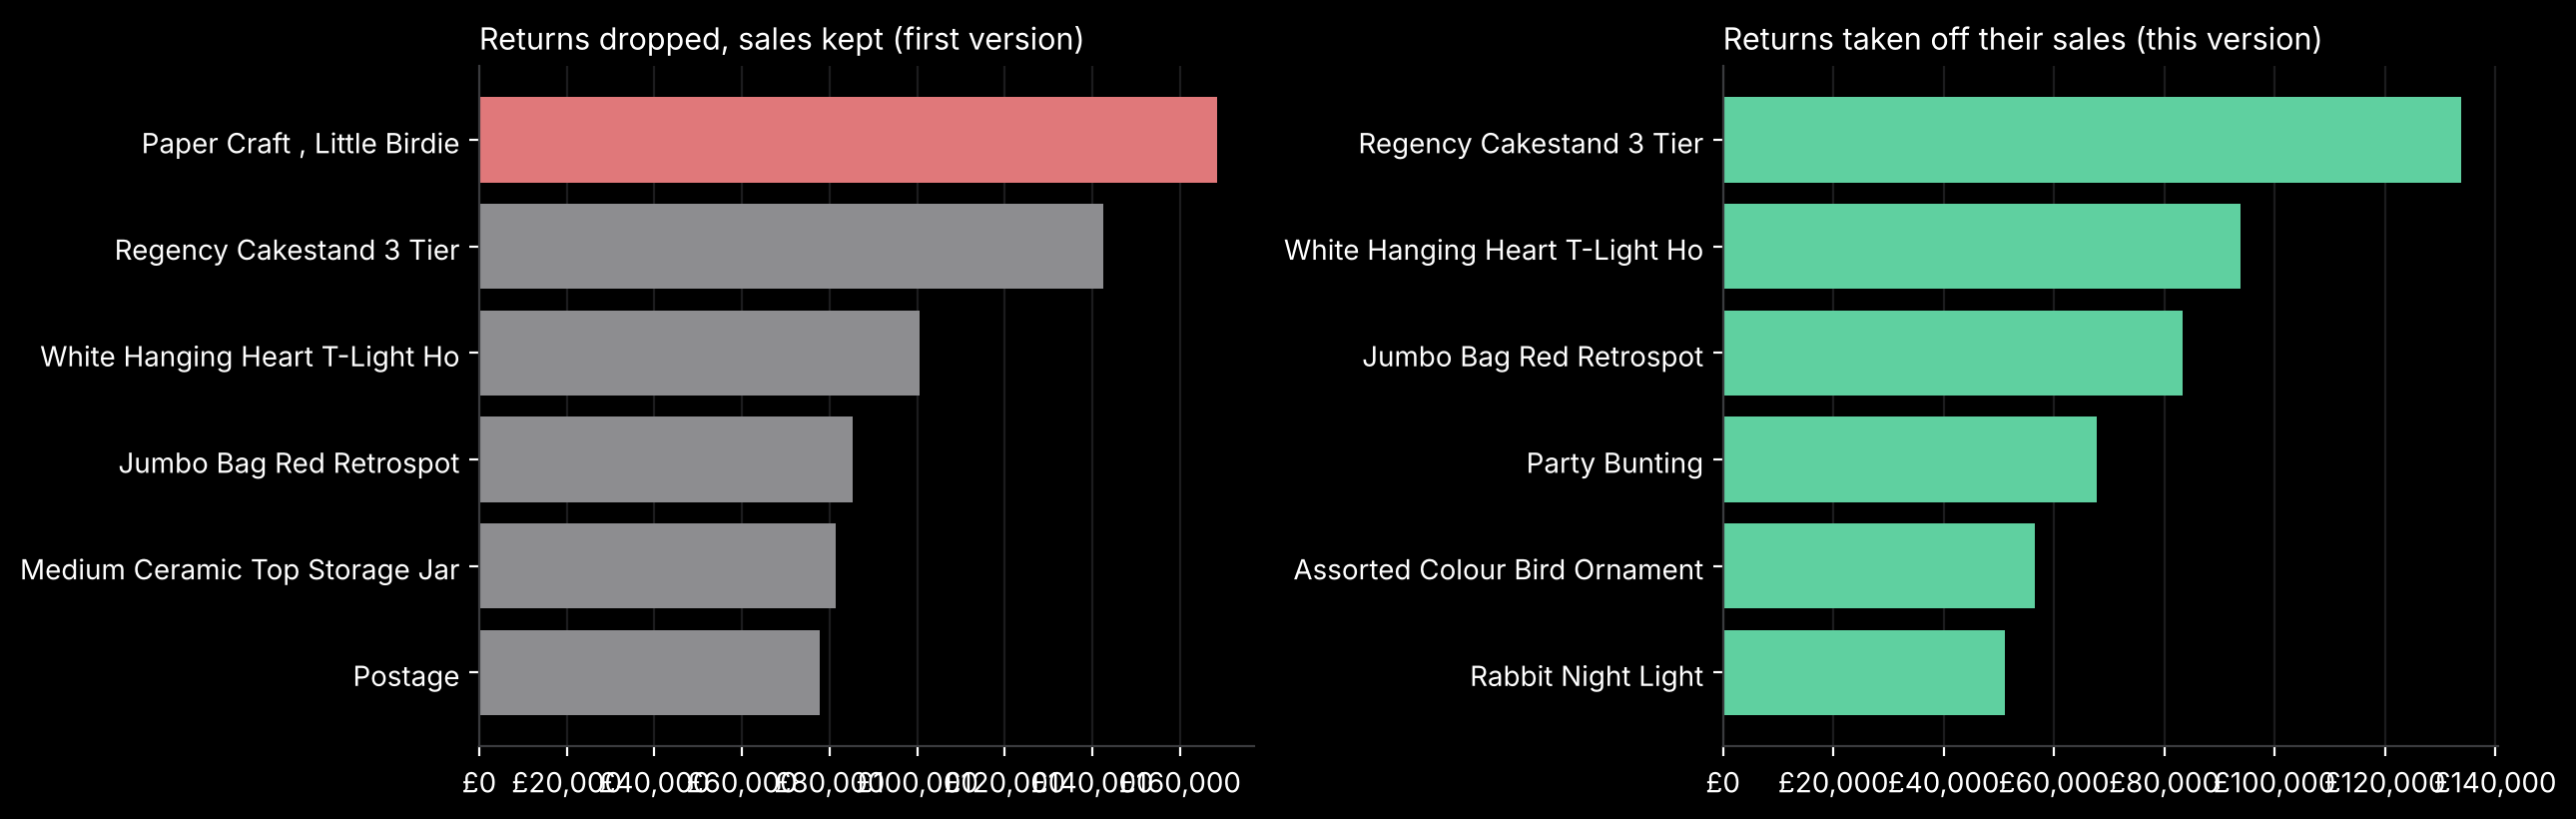

Revenue, first version: £8,911,408    this version: £8,272,854    difference: 7.2%


In [4]:
naive = raw.dropna(subset=["customer"])
naive = naive[(naive.quantity > 0) & (naive.price > 0)].assign(revenue=lambda t: t.quantity * t.price)
fig, axes = plt.subplots(1, 2, figsize=(13, 4.2))
for ax, table, title, color in [(axes[0], naive, "Returns dropped, sales kept (first version)", GREY), (axes[1], sales, "Returns taken off their sales (this version)", JADE)]:
    top = table.groupby("name")["revenue"].sum().nlargest(6)[::-1]
    ax.barh([n.title()[:30] for n in top.index], top.values, color=[RED if "BIRDIE" in n else color for n in top.index])
    ax.set_title(title, loc="left", fontsize=11); ax.xaxis.set_major_formatter(money); ax.grid(axis="y", visible=False)
plt.tight_layout(); plt.show()
print(f"Revenue, first version: £{naive.revenue.sum():,.0f}    this version: £{sales.revenue.sum():,.0f}    difference: {1 - sales.revenue.sum() / naive.revenue.sum():.1%}")

## The cleaned year at a glance

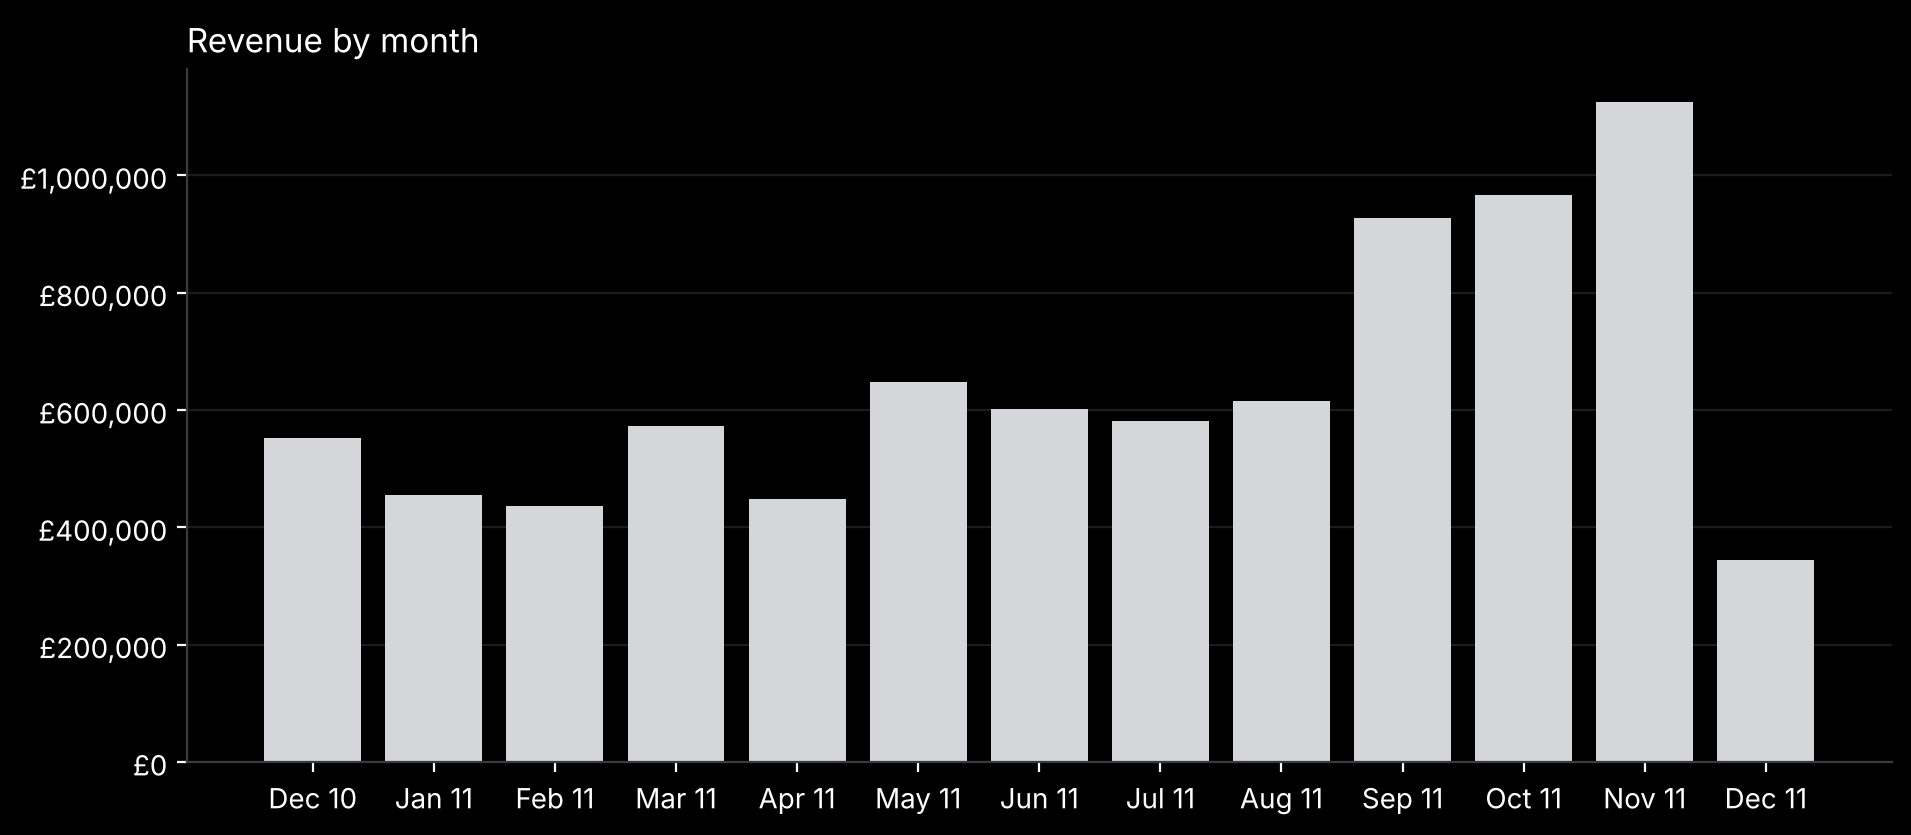

4,324 customers, 18,268 orders, 3,645 products, £8,272,854 revenue
December 2011 is a part month: the data ends on December 09


In [5]:
monthly = sales.set_index("when")["revenue"].resample("MS").sum()
fig, ax = plt.subplots()
ax.bar(monthly.index.strftime("%b %y"), monthly.values, color=SILVER)
ax.yaxis.set_major_formatter(money); ax.set_title("Revenue by month", loc="left"); ax.grid(axis="x", visible=False)
plt.show()
print(f"{sales.customer.nunique():,} customers, {sales.order.nunique():,} orders, {sales['product'].nunique():,} products, £{sales.revenue.sum():,.0f} revenue")
print(f"December 2011 is a part month: the data ends on {sales.when.max():%B %d}")

## What this says

* Returns have to be matched to the sales they undo. Dropping them alone overstated revenue by about 7 percent and put a cancelled order at the top of the product list.
* The business is seasonal, building from September into November.
* About a quarter of the rows have no customer on them. They are left out here because everything that follows is about customers.